# Notebook 03b · Speaker-attributed transcripts: diarization + Whisper

Adds **Whisper** to a diarization system and scores the result: each word gets a speaker, then **tcpWER**.

* **Model 1:** set `DIARIZATION_SOURCE = "rttm"` and `RTTM_SOURCE` to the Model 1 answers from Notebook 03a (`.../model1_headset_test`). This gives Model 1's speaker-attributed transcript and tcpWER.
* **Reference system:** `DIARIZATION_SOURCE = "diarizen"` runs the released DiariZen model (no training by us), useful as a comparison only. It is **not** one of our four models.

The table below describes the DiariZen option.

| | |
|---|---|
| Diarization | DiariZen `BUT-FIT/diarizen-wavlm-large-s80-md` (released model) |
| ASR | Whisper `large-v3`, word timestamps |
| Joining | each Whisper word gets the DiariZen speaker it overlaps most |
| Test data | the same **16 AMI test meetings** as Notebook 02 (Mix-Headset, `only_words`) |
| Scoring | DER exactly as Notebook 02 (collar 0, overlap scored) + overlap DER + **tcpWER** (MeetEval, 5 s collar) |
| Runs | **3 seeds** (42, 43, 44), because one run is not a result |

**Our trained Model 1 is in Notebook 03a.** With `DIARIZATION_SOURCE = "rttm"` this notebook only adds Whisper and scoring to its answers, and the 3 seeds are not needed for diarization (one set of answers is read).

**How to run**
1. **Part A** (once): run in the **default** kernel. It creates a separate `diarizen` environment (Python 3.10, PyTorch 2.1.1), like Notebook 01 did for pyannote 2.1.
2. Switch the kernel (top-right) to **Python (DiariZen)**.
3. **Part B**: run everything below it. Finished meetings are saved, so a stopped run can resume (`RESUME_RUN_ID`).

**Needs from Notebooks 01 and 02:** `/workspace/AMI-diarization-setup`, `data_processed/prepared/manifest_all.csv`, `data_processed/tables/words.parquet`, and the baseline run folder `results/pyannote21_baseline/test/20261021_084955`.

## Part A · Create the DiariZen environment
Run in the **default** kernel, only once per volume. Installs DiariZen (with its own pyannote-audio copy), Whisper and MeetEval into `/workspace/envs/diarizen`, tests the GPU, saves the exact package list, and registers the kernel **Python (DiariZen)**.

In [ ]:
# PART A - run in the DEFAULT kernel. Skips everything that already exists.

import sys
import shutil
import subprocess
from pathlib import Path
from datetime import datetime, timezone

WORK       = Path("/workspace")
LOG_DIR    = WORK / "logs"
CONDA_BIN  = WORK / "miniforge3" / "bin" / "conda"          # installed by Notebook 01
ENV        = WORK / "envs" / "diarizen"
ENV_PYTHON = ENV / "bin" / "python"
ENV_PIP    = [str(ENV_PYTHON), "-m", "pip", "install", "-q"]

DIARIZEN_REPO = WORK / "DiariZen"
DIARIZEN_URL  = "https://github.com/BUTSpeechFIT/DiariZen.git"

TORCH_PACKAGES = ["torch==2.1.1", "torchaudio==2.1.1"]
TORCH_INDEX    = "https://download.pytorch.org/whl/cu121"
OTHER_PACKAGES = ["openai-whisper==20240930", "meeteval", "jiwer", "soundfile", "pandas", "pyarrow",
                  "duckdb", "matplotlib", "ipykernel"]

if "envs/" in sys.executable:
    raise RuntimeError("Part A must run in the DEFAULT kernel, not in a project environment.")
if not CONDA_BIN.exists():
    raise FileNotFoundError("Conda not found - run the 'Install conda' cell of Notebook 01 first.")
LOG_DIR.mkdir(exist_ok=True)
STAMP = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")



# 1. DiariZen code (its pyannote-audio copy is a git submodule)

if DIARIZEN_REPO.exists():
    print("DiariZen repo already downloaded - skipping.")
else:
    print("Downloading DiariZen ...")
    subprocess.run(["git", "clone", "--quiet", "--recurse-submodules", DIARIZEN_URL, str(DIARIZEN_REPO)], check=True)

diarizen_commit = subprocess.run(["git", "-C", str(DIARIZEN_REPO), "rev-parse", "HEAD"],
                                 capture_output=True, text=True, check=True).stdout.strip()
print("DiariZen commit:", diarizen_commit)



# 2. Create the environment (only once)

if ENV_PYTHON.exists():
    print("Environment already exists - skipping create and install.")
else:
    if ENV.exists():
        print(f"Found a broken environment (no Python inside) - removing {ENV}")
        shutil.rmtree(ENV)

    print("Creating environment (Python 3.10) ...")
    subprocess.run([str(CONDA_BIN), "create", "-y", "-q", "-p", str(ENV), "python=3.10"], check=True)

    print("Installing PyTorch 2.1.1 (CUDA 12.1) ...")
    subprocess.run(ENV_PIP + TORCH_PACKAGES + ["--index-url", TORCH_INDEX], check=True)

    print("Installing DiariZen and its pyannote-audio copy ...")
    subprocess.run(ENV_PIP + ["-r", str(DIARIZEN_REPO / "requirements.txt")], check=True)
    subprocess.run(ENV_PIP + ["-e", str(DIARIZEN_REPO)], check=True)
    subprocess.run(ENV_PIP + ["-e", str(DIARIZEN_REPO / "pyannote-audio")], check=True)

    print("Installing Whisper, MeetEval and helpers ...")
    subprocess.run(ENV_PIP + OTHER_PACKAGES, check=True)



# 3. Test: imports, GPU, and that torch was not replaced by another version

test_code = """
import sys, torch, whisper, meeteval, pyannote.audio
from diarizen.pipelines.inference import DiariZenPipeline
print("python", sys.version.split()[0], "| torch", torch.__version__, "| pyannote.audio", pyannote.audio.__version__)
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
assert torch.__version__.startswith("2.1.1"), "torch version changed during install: " + torch.__version__
"""
test = subprocess.run([str(ENV_PYTHON), "-c", test_code], capture_output=True, text=True)
print(test.stdout)
if test.returncode != 0:
    print(test.stderr[-2000:])
    raise RuntimeError("Environment test failed - see the message above.")



# 4. Save the exact package list (commit it to configs/ like configs/pyannote21_environment.txt)

freeze = subprocess.run([str(ENV_PYTHON), "-m", "pip", "freeze"], capture_output=True, text=True, check=True).stdout
env_file = LOG_DIR / f"requirements_diarizen_{STAMP}.txt"
env_file.write_text(f"# DiariZen commit {diarizen_commit}\n" + freeze)
print(f"Exact versions ({len(freeze.splitlines())} packages) saved to {env_file}")



# 5. Register the kernel (re-run after a pod restart; the kernel list is not stored in /workspace)

subprocess.run([str(ENV_PYTHON), "-m", "ipykernel", "install", "--user",
                "--name", "diarizen", "--display-name", "Python (DiariZen)"], check=True, capture_output=True)
print("Kernel registered: Python (DiariZen). Now switch the kernel (top-right) and run Part B.")

DiariZen repo already downloaded - skipping.
DiariZen commit: 844f5555b0a98acd0931511fc641a8c5b8ba92c7
Environment already exists - skipping create and install.


## Part B · Settings
From here on, use the kernel **Python (DiariZen)**.

In [2]:
import os
import sys
import json
import random
import shutil
import subprocess
import warnings
from pathlib import Path
from datetime import datetime, timezone
from getpass import getpass

import numpy as np


WORK         = Path("/workspace")
SETUP        = WORK / "AMI-diarization-setup"
PROCESSED    = WORK / "data_processed"
MANIFEST     = PROCESSED / "prepared" / "manifest_all.csv"
TABLES       = PROCESSED / "tables"
WAREHOUSE    = WORK / "warehouse" / "ami.duckdb"
DIARIZEN_REPO = WORK / "DiariZen"
BASELINE_RUN = WORK / "results" / "pyannote21_baseline" / "test" / "20261106_085354"   # Notebook 02



# 1. Are we in the right environment?

print("Python:", sys.version.split()[0], "|", sys.executable)
if "envs/diarizen" not in sys.executable:
    raise RuntimeError("Wrong kernel! Top-right: choose 'Python (DiariZen)'. Part A creates it.")



# 2. What we evaluate (same data and scoring rules as Notebook 02)

SPLIT         = "test"
REFERENCE_SET = "only_words"
COLLAR        = 0.0
SKIP_OVERLAP  = False
TCPWER_COLLAR = 5.0          # MeetEval recommendation, Workbook 1 AI2



# 3. Which speaker labels to use

DIARIZATION_SOURCE = "rttm"        # "rttm" = answers from another notebook; "diarizen" = released DiariZen
SYSTEM         = "baseline"        # "model1" = Notebook 03a's answers; "baseline" = Notebook 02's answers
RTTM_SOURCE    = WORK / "results" / "pyannote21_baseline" / "test" / "20261106_085354" / "rttm"
REUSE_ASR_FROM = WORK / "results" / "model1_attributed_asr" / "test" / "20261107_065012"   # same Whisper words as Model 1
DIARIZEN_MODEL = "BUT-FIT/diarizen-wavlm-large-s80-md"
WHISPER_MODEL  = "large-v3"
LANGUAGE       = "en"
MAX_WORD_GAP   = 1.0         # seconds; words further apart start a new transcript segment
NEAREST_TURN   = 0.5         # seconds; a word outside every turn takes the nearest turn within this distance
SEEDS          = [42, 43, 44] if DIARIZATION_SOURCE == "diarizen" else [0]

# Targets from Workbook 1 (fixed before any Model 1 result)
TARGETS = {"DER_%": 18.9,              # AI1: match or beat the published baseline
           "DER_overlap_%": 33.82}     # AI2: >= 10% better than the reproduced baseline's 37.58% in overlap



# 4. Run ID and output folder (set RESUME_RUN_ID to continue a stopped run)

RUN_ID = datetime.now(timezone.utc).strftime("%Y%m%d_%H%M%S")
RESUME_RUN_ID = None
if RESUME_RUN_ID:
    RUN_ID = RESUME_RUN_ID

assert SYSTEM in ("model1", "baseline"), SYSTEM
OUT = WORK / "results" / (f"{SYSTEM}_attributed_asr" if DIARIZATION_SOURCE == "rttm" else "diarizen_reference_asr") / SPLIT / RUN_ID
if DIARIZATION_SOURCE == "rttm":
    assert RTTM_SOURCE.exists(), f"RTTM folder not found: {RTTM_SOURCE}"
ASR_DIR = OUT / "asr"                     # Whisper output is the same for every seed, so it is saved once
for folder in [ASR_DIR, OUT / "figures"]:
    folder.mkdir(parents=True, exist_ok=True)

if REUSE_ASR_FROM:
    copied = [shutil.copy(f, ASR_DIR) for f in sorted((Path(REUSE_ASR_FROM) / "asr").glob("*.json"))]
    assert copied, f"No Whisper output in {REUSE_ASR_FROM}/asr"
    print(f"Reusing Whisper output for {len(copied)} meetings from {REUSE_ASR_FROM}")



# 5. Hugging Face token (RunPod secret HF_TOKEN, or typed in; never saved)

HF_TOKEN = os.environ.get("HF_TOKEN")
if not HF_TOKEN:
    HF_TOKEN = getpass("Paste your Hugging Face token: ")
    os.environ["HF_TOKEN"] = HF_TOKEN



# 6. Save this run's settings

import torch
GPU_NAME = torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT AVAILABLE"
if GPU_NAME == "NOT AVAILABLE":
    raise RuntimeError("No GPU - Model 1 on 9 hours of audio needs a GPU.")

run_info = {
    "run_id": RUN_ID, "system": SYSTEM, "diarization_source": DIARIZATION_SOURCE, "rttm_source": str(RTTM_SOURCE),
    "reuse_asr_from": str(REUSE_ASR_FROM) if REUSE_ASR_FROM else None,
    "split": SPLIT, "reference_set": REFERENCE_SET, "collar": COLLAR, "skip_overlap": SKIP_OVERLAP,
    "tcpwer_collar": TCPWER_COLLAR, "diarizen_model": DIARIZEN_MODEL, "whisper_model": WHISPER_MODEL,
    "seeds": SEEDS, "targets": TARGETS, "gpu": GPU_NAME,
}
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2))

print("GPU:", GPU_NAME)
print("System:", SYSTEM, "| Split:", SPLIT, "| Run ID:", RUN_ID, "(UTC) | seeds:", SEEDS)
print("Results go to:", OUT)


Python: 3.10.22 | /workspace/envs/diarizen/bin/python
Reusing Whisper output for 16 meetings from /workspace/results/model1_attributed_asr/test/20261107_065012
GPU: NVIDIA GeForce RTX 4090
System: baseline | Split: test | Run ID: 20261107_085137 (UTC) | seeds: [0]
Results go to: /workspace/results/baseline_attributed_asr/test/20261107_085137


## Imports and versions
Records the exact library versions and the DiariZen code version for this run.

In [3]:
import time
import hashlib
import platform
import importlib.metadata

import pandas as pd
import matplotlib.pyplot as plt
import soundfile as sf
import whisper
from whisper.normalizers import EnglishTextNormalizer
from pyannote.core import Annotation, Segment, Timeline
from pyannote.database.util import load_rttm, load_uem
from pyannote.metrics.diarization import DiarizationErrorRate
from diarizen.pipelines.inference import DiariZenPipeline

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)


def version_of(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return "not installed"


diarizen_commit = subprocess.run(["git", "-C", str(DIARIZEN_REPO), "rev-parse", "HEAD"],
                                 capture_output=True, text=True).stdout.strip() or "unknown"

versions = {
    "python":           platform.python_version(),
    "torch":            torch.__version__,
    "pyannote.audio":   version_of("pyannote.audio"),
    "pyannote.metrics": version_of("pyannote.metrics"),
    "openai-whisper":   version_of("openai-whisper"),
    "meeteval":         version_of("meeteval"),
    "jiwer":            version_of("jiwer"),
    "diarizen_commit":  diarizen_commit,
    "gpu":              GPU_NAME,
}
for name, version in versions.items():
    print(f"{name:17s}: {version}")

run_info["versions"] = versions
(OUT / "run_info.json").write_text(json.dumps(run_info, indent=2))

/workspace/DiariZen/pyannote-audio/pyannote/audio/pipelines/speaker_verification.py:43: UserWarning: Module 'speechbrain.pretrained' was deprecated, redirecting to 'speechbrain.inference'. Please update your script. This is a change from SpeechBrain 1.0. See: https://github.com/speechbrain/speechbrain/releases/tag/v1.0.0
  from speechbrain.pretrained import (


python           : 3.10.22
torch            : 2.1.1+cu121
pyannote.audio   : 3.1.1
pyannote.metrics : 3.2.1
openai-whisper   : 20240930
meeteval         : 0.4.3
jiwer            : 4.0.0
diarizen_commit  : 844f5555b0a98acd0931511fc641a8c5b8ba92c7
gpu              : NVIDIA GeForce RTX 4090


916

## Load the test meetings
The same 16 meetings as Notebook 02, checked three ways: the official list, the audio fingerprints from Notebook 01, and the total length (9.06 h).

In [4]:
# 1. Meetings of this split, from Notebook 01's prepared manifest

manifest = pd.read_csv(MANIFEST)
manifest = manifest[manifest["split"] == SPLIT].reset_index(drop=True)
meetings = manifest["meeting"].tolist()



# 2. Check: exactly the official list

official = set((SETUP / "lists" / f"{SPLIT}.meetings.txt").read_text().split())
assert set(meetings) == official, f"Lists differ! Missing: {official - set(meetings)}, extra: {set(meetings) - official}"



# 3. Check: same audio files as Notebook 01 (SHA-256)

def sha256_of(path, block_size=8 * 1024 * 1024):

    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(block_size), b""):
            digest.update(block)
    return digest.hexdigest()

audio_of = {row.meeting: WORK / row.audio_path for row in manifest.itertuples()}
different = [row.meeting for row in manifest.itertuples() if sha256_of(audio_of[row.meeting]) != row.audio_sha256]
assert not different, f"Audio differs from Notebook 01's manifest for {different}!"



# 4. Reference speakers (RTTM) and scored regions (UEM), the files Notebook 02 used

references = {m: load_rttm(SETUP / REFERENCE_SET / "rttms" / SPLIT / f"{m}.rttm")[m] for m in meetings}
uems       = {m: load_uem(SETUP / "uems" / SPLIT / f"{m}.uem")[m] for m in meetings}

hours = sum(uems[m].duration() for m in meetings) / 3600
print(f"{len(meetings)} meetings | {hours:.2f} hours scored (Notebook 02: 9.06)")
print("All meetings match the official list and Notebook 01's audio fingerprints.")

16 meetings | 9.06 hours scored (Notebook 02: 9.06)
All meetings match the official list and Notebook 01's audio fingerprints.


## Reference transcripts for tcpWER
Built from Notebook 01's `words.parquet` (AMI manual word timings). Words of one person are joined into a segment until there is a pause longer than `MAX_WORD_GAP`. Reference and Whisper text go through the **same** Whisper English normalizer, so spelling style ("okay" vs "OK") is not counted as an error.

Saved as STM files (one line per segment: `meeting 1 speaker start end words`), the format MeetEval reads.

In [5]:
normalizer = EnglishTextNormalizer()


def to_segments(words, max_gap=MAX_WORD_GAP):
    """Join time-sorted words of ONE speaker into segments split at pauses longer than max_gap."""

    segments, current = [], None
    for w in words:
        if current is not None and w["start"] - current["end"] <= max_gap:
            current["end"] = max(current["end"], w["end"])
            current["words"].append(w["word"])
        else:
            if current is not None:
                segments.append(current)
            current = {"start": w["start"], "end": w["end"], "words": [w["word"]]}
    if current is not None:
        segments.append(current)
    return segments


def write_stm(rows, path):
    """rows: dicts with meeting, speaker, start, end, text. Empty texts are skipped."""

    lines = [f"{r['meeting']} 1 {r['speaker']} {r['start']:.3f} {r['end']:.3f} {r['text']}"
             for r in sorted(rows, key=lambda r: (r["meeting"], r["start"])) if r["text"]]
    Path(path).write_text("\n".join(lines) + "\n")
    return len(lines)



# 1. Spoken words of the test meetings

words_table = pd.read_parquet(TABLES / "words.parquet")
ref_words = words_table[(words_table["split"] == SPLIT) & (~words_table["is_punct"])].sort_values(["meeting", "start"])
print(f"Reference words: {len(ref_words):,} in {ref_words['meeting'].nunique()} meetings")



# 2. Segments per person, normalized text

reference_rows = []
for (meeting, speaker), group in ref_words.groupby(["meeting", "speaker"]):
    for seg in to_segments(group[["word", "start", "end"]].to_dict("records")):
        reference_rows.append({"meeting": meeting, "speaker": speaker, "start": seg["start"], "end": seg["end"],
                               "text": normalizer(" ".join(seg["words"])).strip()})

REFERENCE_STM = OUT / "reference.stm"
n_lines = write_stm(reference_rows, REFERENCE_STM)
print(f"Reference segments: {n_lines:,} -> {REFERENCE_STM}")

Reference words: 88,828 in 16 meetings
Reference segments: 6,515 -> /workspace/results/baseline_attributed_asr/test/20261107_085137/reference.stm


## Load Model 1
DiariZen for "who spoke when", Whisper for the words.

**Leakage check (fill in before reporting):** DiariZen's `s80-md` model was trained on several meeting datasets. Read its model card and confirm that **none of our 16 AMI test meetings** were in its training data, and write the answer in `LEAKAGE_NOTE`. If AMI test meetings were used for training, its scores cannot be compared with the baseline.

In [6]:
LEAKAGE_NOTE = "TODO: confirm from the model card that AMI test meetings were not in DiariZen's training data"



# 1. Load

diarizer = None
if DIARIZATION_SOURCE == "diarizen":
    start = time.time()
    diarizer = DiariZenPipeline.from_pretrained(DIARIZEN_MODEL)
    print(f"DiariZen loaded in {time.time() - start:.1f} s")
else:
    print("Diarization answers are read from", RTTM_SOURCE)

start = time.time()
asr_model = whisper.load_model(WHISPER_MODEL, device="cuda")
print(f"Whisper {WHISPER_MODEL} loaded in {time.time() - start:.1f} s")



# 2. Check: Whisper is on the GPU

assert next(asr_model.parameters()).is_cuda, "Whisper is not on the GPU!"



# 3. Save

(OUT / "pipeline_settings.json").write_text(json.dumps({
    "diarizen_model": DIARIZEN_MODEL, "whisper_model": WHISPER_MODEL, "language": LANGUAGE,
    "max_word_gap_s": MAX_WORD_GAP, "nearest_turn_s": NEAREST_TURN, "seeds": SEEDS,
    "leakage_note": LEAKAGE_NOTE, "versions": versions,
}, indent=2))
print("Saved:", OUT / "pipeline_settings.json")

Diarization answers are read from /workspace/results/pyannote21_baseline/test/20261106_085354/rttm
Whisper large-v3 loaded in 18.2 s
Saved: /workspace/results/baseline_attributed_asr/test/20261107_085137/pipeline_settings.json


## The three steps of Model 1
1. **Diarize**: DiariZen answers "who spoke when". Saved as RTTM per meeting and seed.
2. **Transcribe**: Whisper with word timestamps. Greedy decoding (`temperature=0`), so the words do not depend on the seed. Saved once per meeting.
3. **Join**: each word gets the speaker whose turn overlaps it most. A word outside every turn takes the nearest turn within 0.5 s, otherwise `unknown` (Workbook 1, F2: every segment has a speaker or an explicit "unknown").

In [7]:
def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def load_audio(path):

    audio, rate = sf.read(str(path), dtype="float32", always_2d=False)
    if audio.ndim > 1:
        audio = audio[:, 0]
    assert rate == 16000, f"{path}: expected 16 kHz, found {rate}"
    return audio


def diarize(meeting, rttm_file):
    """DiariZen on one meeting. Loads the saved RTTM if this meeting was already done."""

    if rttm_file.exists():
        return load_rttm(rttm_file).get(meeting, Annotation(uri=meeting)), None
    if DIARIZATION_SOURCE == "rttm":
        source = RTTM_SOURCE / f"{meeting}.rttm"
        assert source.exists(), f"No answer for {meeting} in {RTTM_SOURCE}"
        rttm_file.write_text(source.read_text())
        return load_rttm(rttm_file).get(meeting, Annotation(uri=meeting)), None

    start = time.perf_counter()
    result = diarizer(str(audio_of[meeting]), sess_name=meeting)
    seconds = time.perf_counter() - start
    if not isinstance(result, Annotation):
        raise TypeError(f"DiariZen returned {type(result)} - check the DiariZen README for the current API.")

    result.uri = meeting
    temporary = rttm_file.with_name(rttm_file.name + ".part")
    with open(temporary, "w") as out:
        result.write_rttm(out)
    temporary.replace(rttm_file)
    return result, seconds


def transcribe(meeting):
    """Whisper with word timestamps. Saved once; the same words are used for every seed."""

    cache = ASR_DIR / f"{meeting}.json"
    if cache.exists():
        saved = json.loads(cache.read_text())
        return saved["words"], saved["seconds"]

    start = time.perf_counter()
    result = asr_model.transcribe(load_audio(audio_of[meeting]), language=LANGUAGE, word_timestamps=True,
                                  temperature=0.0, condition_on_previous_text=False, fp16=True)
    seconds = time.perf_counter() - start

    words = [{"word": w["word"].strip(), "start": float(w["start"]), "end": float(w["end"]),
              "probability": float(w.get("probability", float("nan")))}
             for segment in result["segments"] for w in segment.get("words", []) if w["word"].strip()]

    temporary = cache.with_name(cache.name + ".part")
    temporary.write_text(json.dumps({"meeting": meeting, "seconds": seconds, "words": words}))
    temporary.replace(cache)
    return words, seconds


def assign_speakers(words, diarization):
    """Give each word the speaker whose turns overlap it most (or the nearest turn, or 'unknown')."""

    turns = [(seg.start, seg.end, label) for seg, _, label in diarization.itertracks(yield_label=True)]
    starts = np.array([t[0] for t in turns]) if turns else np.zeros(0)
    ends   = np.array([t[1] for t in turns]) if turns else np.zeros(0)
    labels = [t[2] for t in turns]

    attributed = []
    for w in words:
        overlap = np.minimum(ends, w["end"]) - np.maximum(starts, w["start"])
        speaker = "unknown"
        if len(turns) and overlap.max() > 0:
            per_label = {}
            for i in np.flatnonzero(overlap > 0):
                per_label[labels[i]] = per_label.get(labels[i], 0.0) + overlap[i]
            speaker = max(per_label, key=per_label.get)
        elif len(turns):
            distance = np.maximum(starts - w["end"], w["start"] - ends)
            nearest = int(np.argmin(distance))
            if distance[nearest] <= NEAREST_TURN:
                speaker = labels[nearest]
        attributed.append({**w, "speaker": str(speaker)})
    return attributed


def hypothesis_rows(meeting, attributed_words):
    """Speaker-attributed transcript segments of one meeting, normalized like the reference."""

    rows = []
    frame = pd.DataFrame(attributed_words)
    if frame.empty:
        return rows
    for speaker, group in frame.sort_values("start").groupby("speaker"):
        for seg in to_segments(group[["word", "start", "end"]].to_dict("records")):
            rows.append({"meeting": meeting, "speaker": f"{meeting}_{speaker}", "start": seg["start"],
                         "end": seg["end"], "text": normalizer(" ".join(seg["words"])).strip(),
                         "raw_text": " ".join(seg["words"])})
    return rows

## Run Model 1 on every meeting, for every seed
For each seed: diarize all 16 meetings, score DER (overall, in overlap, outside overlap) exactly like Notebook 02, transcribe (once), join words to speakers, and save the speaker-attributed transcript. Whisper runs only in the first seed; later seeds reuse its saved words.

**Time:** about 9 hours of audio. Expect roughly 1-2 hours for the first seed on an A40 (Whisper is the slow part), less for the next seeds. Everything is saved per meeting, so set `RESUME_RUN_ID` and re-run to continue after an interruption.

In [8]:
rows = []
hypotheses = {}            # (seed, meeting) -> Annotation
attributed = {}            # (seed, meeting) -> words with speakers
pooled = {}                # seed -> dict of pooled DER metrics

for seed in SEEDS:
    set_seed(seed)
    seed_out = OUT / f"seed_{seed}"
    (seed_out / "rttm").mkdir(parents=True, exist_ok=True)

    metric          = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
    der_overlap     = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
    der_non_overlap = DiarizationErrorRate(collar=COLLAR, skip_overlap=SKIP_OVERLAP)
    seed_hyp_rows   = []

    for i, meeting in enumerate(meetings, start=1):
        reference = references[meeting]
        uem       = uems[meeting]
        audio_s   = uem.duration()


        # 1. Who spoke when

        hypothesis, diar_s = diarize(meeting, seed_out / "rttm" / f"{meeting}.rttm")
        hypotheses[(seed, meeting)] = hypothesis


        # 2. Score DER exactly like Notebook 02

        d     = metric(reference, hypothesis, uem=uem, detailed=True)
        total = d["total"]
        overlap_region     = reference.get_timeline().get_overlap().crop(uem)
        non_overlap_region = overlap_region.gaps(support=uem)
        ov  = der_overlap(reference, hypothesis, uem=overlap_region)
        non = der_non_overlap(reference, hypothesis, uem=non_overlap_region)


        # 3. Words, then words with speakers

        words, asr_s = transcribe(meeting)
        start = time.perf_counter()
        words_with_speaker = assign_speakers(words, hypothesis)
        align_s = time.perf_counter() - start
        attributed[(seed, meeting)] = words_with_speaker
        seed_hyp_rows += hypothesis_rows(meeting, words_with_speaker)

        rows.append({
            "seed":                 seed,
            "meeting":              meeting,
            "DER_%":                100 * d["diarization error rate"],
            "missed_%":             100 * d["missed detection"] / total,
            "false_alarm_%":        100 * d["false alarm"] / total,
            "confusion_%":          100 * d["confusion"] / total,
            "DER_overlap_%":        100 * ov,
            "DER_non_overlap_%":    100 * non,
            "overlap_min":          overlap_region.duration() / 60,
            "reference_speech_min": total / 60,
            "predicted_speakers":   len(hypothesis.labels()),
            "reference_speakers":   len(reference.labels()),
            "words":                len(words),
            "unknown_word_%":       100 * np.mean([w["speaker"] == "unknown" for w in words_with_speaker]) if words else np.nan,
            "diarization_s":        diar_s,
            "asr_s":                asr_s,
            "align_s":              align_s,
            "audio_s":              audio_s,
        })

        timing = "loaded from disk" if diar_s is None else f"diarization {diar_s / 60:.1f} min"
        print(f"[seed {seed} | {i:2d}/{len(meetings)}] {meeting}: DER {rows[-1]['DER_%']:5.2f}% "
              f"| overlap DER {rows[-1]['DER_overlap_%']:5.1f}% "
              f"| speakers {rows[-1]['predicted_speakers']} vs {rows[-1]['reference_speakers']} ({timing})")


    # 4. Pooled DER of this seed, and its speaker-attributed transcript (STM for MeetEval, JSON for us)

    report = metric.report(display=False)
    total_row = report.loc["TOTAL"]
    speech = total_row[("total", "")]
    pooled[seed] = {
        "DER_%":             abs(metric) * 100,
        "missed_%":          100 * total_row[("missed detection", "")] / speech,
        "false_alarm_%":     100 * total_row[("false alarm", "")] / speech,
        "confusion_%":       100 * total_row[("confusion", "")] / speech,
        "DER_overlap_%":     abs(der_overlap) * 100,
        "DER_non_overlap_%": abs(der_non_overlap) * 100,
    }
    report.to_csv(seed_out / "pyannote_metric_report.csv")
    write_stm(seed_hyp_rows, seed_out / "hypothesis.stm")
    pd.DataFrame(seed_hyp_rows).to_json(seed_out / "transcript_segments.json", orient="records", indent=1)
    print(f"--> seed {seed}: pooled DER {pooled[seed]['DER_%']:.2f}% | overlap DER {pooled[seed]['DER_overlap_%']:.2f}%\n")

results = pd.DataFrame(rows)
results.to_csv(OUT / "per_meeting_results.csv", index=False)
print("All seeds done ✓  Saved:", OUT / "per_meeting_results.csv")

[seed 0 |  1/16] IS1009a: DER 21.15% | overlap DER  39.3% | speakers 4 vs 4 (loaded from disk)
[seed 0 |  2/16] IS1009b: DER 13.65% | overlap DER  40.3% | speakers 5 vs 4 (loaded from disk)
[seed 0 |  3/16] IS1009c: DER 12.30% | overlap DER  45.9% | speakers 6 vs 4 (loaded from disk)
[seed 0 |  4/16] IS1009d: DER 16.77% | overlap DER  38.3% | speakers 4 vs 4 (loaded from disk)
[seed 0 |  5/16] ES2004a: DER 19.18% | overlap DER  36.2% | speakers 4 vs 4 (loaded from disk)
[seed 0 |  6/16] ES2004b: DER 12.61% | overlap DER  31.2% | speakers 4 vs 4 (loaded from disk)
[seed 0 |  7/16] ES2004c: DER 12.96% | overlap DER  28.6% | speakers 4 vs 4 (loaded from disk)
[seed 0 |  8/16] ES2004d: DER 20.61% | overlap DER  31.6% | speakers 5 vs 4 (loaded from disk)
[seed 0 |  9/16] TS3003a: DER 19.33% | overlap DER  45.2% | speakers 2 vs 4 (loaded from disk)
[seed 0 | 10/16] TS3003b: DER 12.66% | overlap DER  35.9% | speakers 4 vs 4 (loaded from disk)
[seed 0 | 11/16] TS3003c: DER 14.56% | overlap DER

## Word error rates: tcpWER and plain WER
- **tcpWER** (MeetEval, 5 s collar): a word only counts as correct if it is given to the **right speaker** at roughly the **right time**. This is the main ASR metric in Workbook 1.
- **WER** (jiwer): the same words with speakers and times ignored.

The gap between the two is roughly what **speaker attribution costs** in word errors. This connects to the project's main question.

In [9]:
import jiwer

MEETEVAL = Path(sys.executable).parent / "meeteval-wer"


def find_error_rate(record):
    """MeetEval output files hold an 'error_rate' field; look for it at any depth."""

    if isinstance(record, dict):
        if "error_rate" in record:
            return float(record["error_rate"])
        for value in record.values():
            found = find_error_rate(value)
            if found is not None:
                return found
    return None


def run_tcpwer(reference_stm, hypothesis_stm, out_dir):
    """Run MeetEval tcpWER; returns (pooled %, {meeting: %})."""

    out_dir.mkdir(parents=True, exist_ok=True)
    hyp_copy = out_dir / "hypothesis.stm"
    hyp_copy.write_text(Path(hypothesis_stm).read_text())
    done = subprocess.run([str(MEETEVAL), "tcpwer", "-r", str(reference_stm), "-h", str(hyp_copy),
                           "--collar", f"{TCPWER_COLLAR:g}"], capture_output=True, text=True, cwd=out_dir)

    if done.returncode != 0:
        print(done.stderr[-2000:])
        raise RuntimeError("meeteval-wer failed - see the message above.")

    average_files = [f for f in out_dir.glob("*tcpwer*.json") if "per_reco" not in f.name]
    per_reco_files = list(out_dir.glob("*tcpwer*per_reco*.json"))
    assert average_files and per_reco_files, f"MeetEval output files not found in {out_dir}: {list(out_dir.iterdir())}"
    pooled_rate = find_error_rate(json.loads(average_files[0].read_text()))
    per_meeting = {m: find_error_rate(v) for m, v in json.loads(per_reco_files[0].read_text()).items()}
    return 100 * pooled_rate, {m: 100 * v for m, v in per_meeting.items() if v is not None}


def plain_wer(seed):
    """Speaker-agnostic WER over all meetings (time-ordered words, speakers ignored)."""

    refs, hyps = [], []
    for meeting in meetings:
        ref_text = normalizer(" ".join(ref_words.loc[ref_words["meeting"] == meeting, "word"]))
        hyp_text = normalizer(" ".join(w["word"] for w in sorted(attributed[(seed, meeting)], key=lambda w: w["start"])))
        refs.append(ref_text)
        hyps.append(hyp_text)
    return 100 * jiwer.process_words(refs, hyps).wer



# 1. tcpWER and WER for every seed

for seed in SEEDS:
    seed_out = OUT / f"seed_{seed}"
    tcp_pooled, tcp_per_meeting = run_tcpwer(REFERENCE_STM, seed_out / "hypothesis.stm", seed_out / "meeteval")
    pooled[seed]["tcpWER_%"] = tcp_pooled
    pooled[seed]["WER_%"]    = plain_wer(seed)
    results.loc[results["seed"] == seed, "tcpWER_%"] = results.loc[results["seed"] == seed, "meeting"].map(tcp_per_meeting)
    print(f"seed {seed}: tcpWER {tcp_pooled:.2f}% | WER (speakers ignored) {pooled[seed]['WER_%']:.2f}% "
          f"| attribution cost ~ {tcp_pooled - pooled[seed]['WER_%']:.2f} points")

results.to_csv(OUT / "per_meeting_results.csv", index=False)

seed 0: tcpWER 35.35% | WER (speakers ignored) 24.90% | attribution cost ~ 10.45 points


## Model 1 vs the reproduced baseline
Mean and spread over the 3 seeds, next to the baseline from Notebook 02, and checked against the Workbook 1 targets (AI1: DER ≤ 18.9%; AI2: overlap DER ≤ 33.82%).

In [10]:
# 1. Mean and standard deviation over seeds

seed_table = pd.DataFrame(pooled).T
seed_table.index.name = "seed"
spread = seed_table.agg(["mean", "std", "min", "max"]).T.round(2)
print(f"Model 1 over {len(SEEDS)} seeds:")
print(spread.to_string(), "\n")



# 2. Baseline from Notebook 02

baseline_summary = None
for candidate in [BASELINE_RUN / "summary.json", Path("outputs/02_baseline_pyannote21/test/summary.json")]:
    if candidate.exists():
        baseline_summary = json.loads(candidate.read_text())
        break
assert baseline_summary is not None, "Baseline summary.json not found - check BASELINE_RUN."

comparison = pd.DataFrame({
    "baseline (pyannote 2.1)": {
        "DER_%": baseline_summary["der_%"], "missed_%": baseline_summary["miss_%"],
        "false_alarm_%": baseline_summary["fa_%"], "confusion_%": baseline_summary["conf_%"],
        "DER_overlap_%": baseline_summary["der_overlap_%"], "DER_non_overlap_%": baseline_summary["der_non_overlap_%"],
        "tcpWER_%": np.nan, "WER_%": np.nan},
    "Model 1 mean": spread["mean"],
    "Model 1 std":  spread["std"],
})
comparison["change (points)"] = (comparison["Model 1 mean"] - comparison["baseline (pyannote 2.1)"]).round(2)
print(comparison.round(2).to_string(), "\n")



# 3. Workbook 1 targets

checks = {
    "AI1: DER <= 18.9%":           spread.loc["DER_%", "mean"] <= TARGETS["DER_%"],
    "AI2: overlap DER <= 33.82%":  spread.loc["DER_overlap_%", "mean"] <= TARGETS["DER_overlap_%"],
}
for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL'}  {name}")

comparison.to_csv(OUT / "comparison_with_baseline.csv")
seed_table.to_csv(OUT / "per_seed_results.csv")

Model 1 over 1 seeds:
                    mean  std    min    max
DER_%              19.52  NaN  19.52  19.52
missed_%            8.65  NaN   8.65   8.65
false_alarm_%       5.27  NaN   5.27   5.27
confusion_%         5.60  NaN   5.60   5.60
DER_overlap_%      38.97  NaN  38.97  38.97
DER_non_overlap_%  12.31  NaN  12.31  12.31
tcpWER_%           35.35  NaN  35.35  35.35
WER_%              24.90  NaN  24.90  24.90 

                   baseline (pyannote 2.1)  Model 1 mean  Model 1 std  change (points)
DER_%                                19.52         19.52          NaN              0.0
missed_%                              8.65          8.65          NaN              0.0
false_alarm_%                         5.27          5.27          NaN              0.0
confusion_%                           5.60          5.60          NaN              0.0
DER_overlap_%                        38.97         38.97          NaN              0.0
DER_non_overlap_%                    12.31         12.31  

## DER per meeting: Model 1 vs baseline
Model 1 bars show the mean over seeds; the thin lines show min-max over seeds.

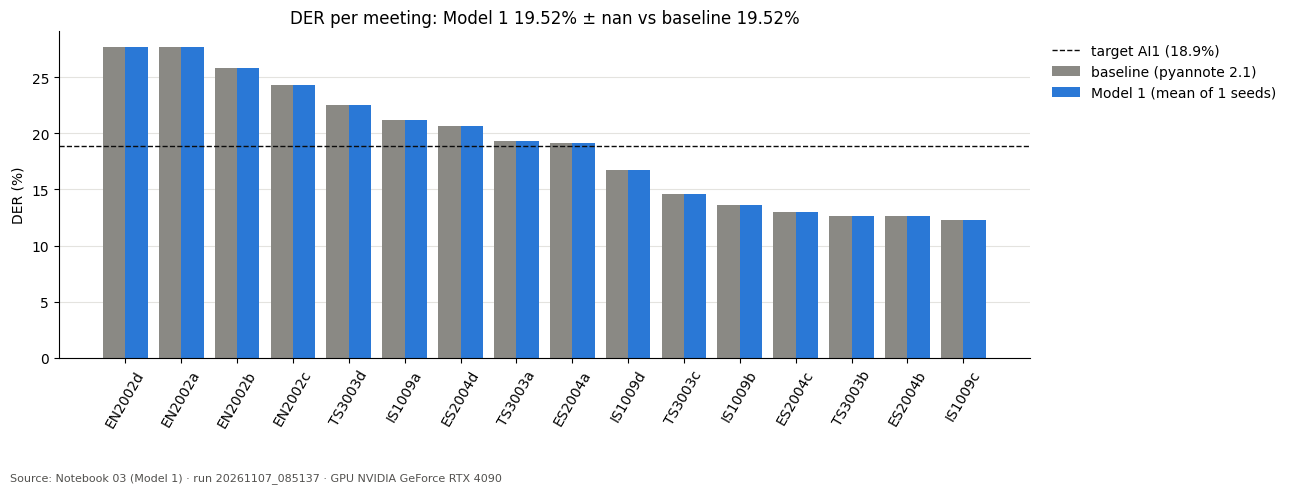

Saved: /workspace/results/baseline_attributed_asr/test/20261107_085137/figures/der_per_meeting_m1_vs_baseline.png


In [11]:
INK, NEUTRAL = "#0b0b0b", "#52514e"
BASE_COLOR, M1_COLOR = "#8a8984", "#2a78d6"

baseline_meetings = pd.read_csv(BASELINE_RUN / "per_meeting_results.csv").set_index("meeting")
m1 = results.groupby("meeting")["DER_%"].agg(["mean", "min", "max"])
order = baseline_meetings["DER_%"].sort_values(ascending=False).index
x = np.arange(len(order))

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.bar(x - 0.2, baseline_meetings.loc[order, "DER_%"], width=0.4, color=BASE_COLOR, label="baseline (pyannote 2.1)")
ax.bar(x + 0.2, m1.loc[order, "mean"], width=0.4, color=M1_COLOR, label=f"Model 1 (mean of {len(SEEDS)} seeds)")
ax.vlines(x + 0.2, m1.loc[order, "min"], m1.loc[order, "max"], color=INK, linewidth=1)

ax.axhline(TARGETS["DER_%"], color=INK, linestyle="--", linewidth=1, label=f"target AI1 ({TARGETS['DER_%']}%)")
ax.set_xticks(x)
ax.set_xticklabels(order, rotation=60)
ax.set_ylabel("DER (%)")
ax.set_title(f"DER per meeting: Model 1 {spread.loc['DER_%', 'mean']:.2f}% ± {spread.loc['DER_%', 'std']:.2f} "
             f"vs baseline {baseline_summary['der_%']}%")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="y", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
fig.text(0.01, -0.08, f"Source: Notebook 03 (Model 1) · run {RUN_ID} · GPU {GPU_NAME}", fontsize=8, color=NEUTRAL)

plt.tight_layout()
figure_file = OUT / "figures" / "der_per_meeting_m1_vs_baseline.png"
plt.savefig(figure_file, dpi=150, bbox_inches="tight")
plt.show()
print("Saved:", figure_file)

## Speed
Time per meeting for each step. Model 1 works on whole recordings (offline), so this is **processing speed (RTF), not live latency**. The p95 ≤ 3 s target (F5) is measured on the streaming model M2 in 298B; Workbook 1 asks 298A to report Model 1's speed as a reference.

In [12]:
# 1. Use only meetings that were really processed in this run (not loaded from disk)

first_seed = results[results["seed"] == SEEDS[0]].copy()
measured = first_seed.dropna(subset=["diarization_s"])
measured = measured.assign(total_s=measured["diarization_s"] + measured["asr_s"] + measured["align_s"])

if len(measured):
    speed = {
        "meetings_measured":  len(measured),
        "diarization_RTF":    round(measured["diarization_s"].sum() / measured["audio_s"].sum(), 4),
        "asr_RTF":            round(measured["asr_s"].sum() / measured["audio_s"].sum(), 4),
        "end_to_end_RTF":     round(measured["total_s"].sum() / measured["audio_s"].sum(), 4),
        "gpu_minutes_total":  round(measured["total_s"].sum() / 60, 1),
        "per_meeting_total_s_p50": round(float(measured["total_s"].quantile(0.50)), 1),
        "per_meeting_total_s_p95": round(float(measured["total_s"].quantile(0.95)), 1),
    }
else:
    speed = {"note": "all meetings were loaded from disk - re-run without RESUME_RUN_ID to measure speed"}
print(json.dumps(speed, indent=2))

{
  "note": "all meetings were loaded from disk - re-run without RESUME_RUN_ID to measure speed"
}


## Final summary and warehouse
All headline numbers in `summary.json`. Per-meeting results and one benchmark row go into the same DuckDB tables as the baseline (`model_results`, `benchmark`), so every model is compared the same way.

In [13]:
import duckdb

MODEL_NAME = {"model1": "M1_finetuned_segmentation_whisper", "baseline": "pyannote2.1_baseline_whisper"}[SYSTEM]



# 1. summary.json

summary = {
    "run_id": RUN_ID, "model": MODEL_NAME, "split": SPLIT, "meetings": len(meetings),
    "runs": len(SEEDS), "seeds": SEEDS, "gpu": GPU_NAME,
    "mean": spread["mean"].to_dict(), "std": spread["std"].to_dict(),
    "min": spread["min"].to_dict(), "max": spread["max"].to_dict(),
    "baseline_der_%": baseline_summary["der_%"], "baseline_der_overlap_%": baseline_summary["der_overlap_%"],
    "targets": TARGETS, "target_checks": {k: bool(v) for k, v in checks.items()},
    "speed": speed, "leakage_note": LEAKAGE_NOTE,
    "scoring": {"collar": COLLAR, "skip_overlap": SKIP_OVERLAP, "tcpwer_collar": TCPWER_COLLAR,
                "reference_set": REFERENCE_SET},
    "versions": versions,
}
(OUT / "summary.json").write_text(json.dumps(summary, indent=2, default=float))
print(json.dumps({k: summary[k] for k in ["mean", "std", "target_checks"]}, indent=2, default=float))



# 2. Warehouse: same columns as Notebook 02, plus seed

STANDARD_COLUMNS = ["meeting", "DER_%", "missed_%", "false_alarm_%", "confusion_%",
                    "DER_overlap_%", "DER_non_overlap_%", "reference_speech_min",
                    "predicted_speakers", "reference_speakers"]

per_meeting_rows = results[STANDARD_COLUMNS + ["seed", "tcpWER_%"]].assign(
    model=MODEL_NAME, split=SPLIT, run_id=RUN_ID)

benchmark_row = pd.DataFrame([{
    "model": MODEL_NAME, "type": f"speaker-attributed ASR ({DIARIZATION_SOURCE})", "split": SPLIT, "run_id": RUN_ID,
    "meetings": len(meetings), "der_%": round(spread.loc["DER_%", "mean"], 2),
    "der_95_low": round(spread.loc["DER_%", "min"], 2), "der_95_high": round(spread.loc["DER_%", "max"], 2),
    "der_overlap_%": round(spread.loc["DER_overlap_%", "mean"], 2), "published_%": None, "gap_points": None,
    "runs": f"{len(SEEDS)} seeds (range = min-max over seeds)", "gpu": GPU_NAME,
    "gpu_min": speed.get("gpu_minutes_total"),
}])


def save(con, table_name, frame):

    con.register("incoming", frame)
    con.execute(f"CREATE TABLE IF NOT EXISTS {table_name} AS SELECT * FROM incoming WHERE 1 = 0")
    existing = {row[0] for row in con.execute(f"DESCRIBE {table_name}").fetchall()}
    for column in frame.columns:                       # new columns (seed, tcpWER) are added once
        if column not in existing:
            con.execute(f'ALTER TABLE {table_name} ADD COLUMN "{column}" DOUBLE')
    con.execute(f"DELETE FROM {table_name} WHERE run_id = ? AND model = ?", [RUN_ID, MODEL_NAME])
    con.execute(f"INSERT INTO {table_name} BY NAME SELECT * FROM incoming")
    con.unregister("incoming")


with duckdb.connect(str(WAREHOUSE)) as con:
    save(con, "model_results", per_meeting_rows)
    save(con, "benchmark", benchmark_row)
    print("\nBenchmark table:")
    print(con.sql("SELECT model, run_id, meetings, \"der_%\", \"der_overlap_%\", runs, gpu FROM benchmark ORDER BY run_id")
             .df().to_string(index=False))

{
  "mean": {
    "DER_%": 19.52,
    "missed_%": 8.65,
    "false_alarm_%": 5.27,
    "confusion_%": 5.6,
    "DER_overlap_%": 38.97,
    "DER_non_overlap_%": 12.31,
    "tcpWER_%": 35.35,
    "WER_%": 24.9
  },
  "std": {
    "DER_%": NaN,
    "missed_%": NaN,
    "false_alarm_%": NaN,
    "confusion_%": NaN,
    "DER_overlap_%": NaN,
    "DER_non_overlap_%": NaN,
    "tcpWER_%": NaN,
    "WER_%": NaN
  },
  "target_checks": {
    "AI1: DER <= 18.9%": false,
    "AI2: overlap DER <= 33.82%": false
  }
}

Benchmark table:
                            model          run_id  meetings  der_%  der_overlap_%                                 runs                     gpu
             pyannote2.1_baseline 20261106_085354        16  19.52          38.97                    1 (deterministic) NVIDIA GeForce RTX 4090
M1_finetuned_segmentation_whisper 20261107_065012        16  19.48          41.91 1 seeds (range = min-max over seeds) NVIDIA GeForce RTX 4090
     pyannote2.1_baseline_whisper 20261107

## Sample transcript for the demo
Writes the first 3 minutes of one meeting as a speaker-attributed transcript in the format `src/demo/app.py` reads:

```bash
python -m src.demo.app --input outputs/model1_sample_transcript.json
```
Copy the file into the repo's `outputs/` folder. It contains AMI words, so **keep it local and do not commit it**.

In [14]:
DEMO_MEETING, DEMO_SECONDS = "IS1009a", 180

demo_rows = [r for r in hypothesis_rows(DEMO_MEETING, attributed[(SEEDS[0], DEMO_MEETING)]) if r["start"] < DEMO_SECONDS]
demo = {
    "status": "model1_output",
    "model": MODEL_NAME, "run_id": RUN_ID, "seed": SEEDS[0], "meeting": DEMO_MEETING,
    "segments": [{"start": round(r["start"], 2), "end": round(r["end"], 2),
                  "speaker": r["speaker"].replace(f"{DEMO_MEETING}_", ""), "text": r["raw_text"]}
                 for r in sorted(demo_rows, key=lambda r: r["start"])],
}
demo_file = OUT / "model1_sample_transcript.json"
demo_file.write_text(json.dumps(demo, indent=2))
print(f"{len(demo['segments'])} segments -> {demo_file}")
for segment in demo["segments"][:8]:
    print(f"[{segment['start']:7.2f}-{segment['end']:7.2f}] {segment['speaker']}: {segment['text']}")

12 segments -> /workspace/results/baseline_attributed_asr/test/20261107_085137/model1_sample_transcript.json
[  15.58-  17.56] unknown: Thank you.
[  54.56-  66.34] SPEAKER_01: Okay. Okay. Everybody ready? I think so. I think the first thing we do is introduce ourselves. Yeah, that's a good plan. And his name and what your function is. So maybe we
[  66.34-  81.86] SPEAKER_02: start with you. Yeah, my name is Francena, and I'm a user interface. My role is the main responsibility is user interface. And my role is to design a television remote control. Okay.
[  83.00-  86.88] SPEAKER_00: And I'm a marketing person. I want to figure out how to sell them.
[  87.58-  88.54] SPEAKER_01: And your name is?
[  88.58-  90.40] SPEAKER_00: My name is Eileen. Okay.
[  90.74-  97.52] SPEAKER_03: Yeah, I'm Janvi. My role is industrial designer and my responsibilities are
[  99.84- 107.12] SPEAKER_03: deal with the technical functional designs and specifications of user interface and dealing with user

## Findings
Write these **after** the run, from the numbers above. Do not change the targets or the metrics.

* **DER vs baseline:** …
* **Overlap DER vs target 33.82%:** …
* **tcpWER and attribution cost:** …
* **Spread over seeds:** …
* **Speed:** …
* **Leakage note:** …